# TSP Optimization with Simulated Annealing and Genetic Algorithms — Assignment Notebook

Works in **Jupyter** and **Google Colab**.

## Overview
You will solve the same TSP instance using **two heuristic optimization methods**:

1. **Simulated Annealing (SA)** with a 2-opt neighborhood  
2. **Genetic Algorithm (GA)** on **permutation tours** (a standard evolutionary approach for TSP)

The notebook provides:
- A reproducible TSP instance generator
- Tour utilities (length, validity)
- A 2-opt neighborhood operator
- Visualization helpers (tour plot + history plot)
- Baseline heuristic: nearest neighbor

## Tasks
### Task A — Simulated Annealing (SA)
Implement `simulated_annealing_tsp(...)`. Find sections with "TODO" to complete the implementations.

### Task B — Genetic Algorithm (GA)
Implement `genetic_algorithm_tsp(...)` plus helper functions:
- Tournament selection
- Order crossover (OX)
- Swap mutation
Find sections with "TODO" to complete the implementations.

## Deliverables
- Completed notebook (or exported `.py`) (find all TODOs and implement them)
- Write a technical report that includes:
  - Descriptions of the problem context, solutions (include important code snippets)
  - Experimental results, present the graphs, plots and data generated from the notebook based on your implementation.
    - SA parameters + best tour length
    - GA parameters + best tour length
    - Brief comparison: which worked better and why
    - More specifics can be found Part 6 below.
    - Optional work done in Part 7 below
  - Analysis of the experimental results.


---


In [1]:
# If running in a fresh environment, uncomment as needed:
# !pip -q install matplotlib numpy

import math
import random
import time
from dataclasses import dataclass
from typing import List, Tuple, Optional, Callable, Dict

import matplotlib.pyplot as plt
import numpy as np


## Part 1 — TSP utilities (provided)

In [2]:
Point = Tuple[float, float]
Tour = List[int]

def make_cities(n: int = 40, seed: int = 7) -> List[Point]:
    # Reproducible 2D city coordinates in [0, 1]x[0, 1].
    rng = random.Random(seed)
    return [(rng.random(), rng.random()) for _ in range(n)]

def dist(a: Point, b: Point) -> float:
    dx = a[0] - b[0]
    dy = a[1] - b[1]
    return math.hypot(dx, dy)

def tour_length(cities: List[Point], tour: Tour) -> float:
    # Total length of a closed tour.
    n = len(tour)
    total = 0.0
    for i in range(n):
        total += dist(cities[tour[i]], cities[tour[(i + 1) % n]])
    return total

def is_valid_tour(tour: Tour, n: int) -> bool:
    return len(tour) == n and set(tour) == set(range(n))

def random_tour(n: int, rng: random.Random) -> Tour:
    t = list(range(n))
    rng.shuffle(t)
    return t

def nearest_neighbor_tour(cities: List[Point], start: int = 0) -> Tour:
    # Deterministic baseline: greedy nearest neighbor.
    n = len(cities)
    unvisited = set(range(n))
    tour = [start]
    unvisited.remove(start)
    cur = start
    while unvisited:
        nxt = min(unvisited, key=lambda j: dist(cities[cur], cities[j]))
        tour.append(nxt)
        unvisited.remove(nxt)
        cur = nxt
    return tour


## Part 2 — Neighborhood operator (2-opt) (provided)

In [3]:
def two_opt_swap(tour: Tour, i: int, k: int) -> Tour:
    # Return a new tour where the segment [i:k] is reversed.
    return tour[:i] + list(reversed(tour[i:k + 1])) + tour[k + 1:]

def random_two_opt_neighbor(tour: Tour, rng: random.Random) -> Tour:
    # Pick a random 2-opt move.
    n = len(tour)
    i = rng.randrange(0, n - 1)
    k = rng.randrange(i + 1, n)
    return two_opt_swap(tour, i, k)


## Part 3 — Visualization helpers (provided)

* You are encouraged to implement more variations of visualization.

In [4]:
def plot_tour(cities: List[Point], tour: Tour, title: str = "") -> None:
    xs = [cities[i][0] for i in tour] + [cities[tour[0]][0]]
    ys = [cities[i][1] for i in tour] + [cities[tour[0]][1]]

    plt.figure(figsize=(6, 6))
    plt.plot(xs, ys, marker="o")
    plt.title(title)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.gca().set_aspect("equal", adjustable="box")
    plt.show()

def plot_history(series: List[float], title: str, ylabel: str = "Value") -> None:
    plt.figure(figsize=(7, 4))
    plt.plot(series)
    plt.title(title)
    plt.xlabel("Iteration")
    plt.ylabel(ylabel)
    plt.show()

def plot_compare(sa_hist: List[float], ga_hist: List[float]) -> None:
    # Overlay histories (x-axis is not identical meaning; this is a visual comparison).
    plt.figure(figsize=(8, 4))
    plt.plot(sa_hist, label="SA best-so-far")
    plt.plot([i * (len(sa_hist) / max(1, len(ga_hist)-1)) for i in range(len(ga_hist))], ga_hist, label="GA best-by-gen")
    plt.title("SA vs GA: Best tour length over time (scaled x-axis)")
    plt.xlabel("Progress (scaled)")
    plt.ylabel("Length")
    plt.legend()
    plt.show()


## Part 4 — Baseline tour (nearest neighbor) (provided)

Nearest-neighbor length: 6.0214


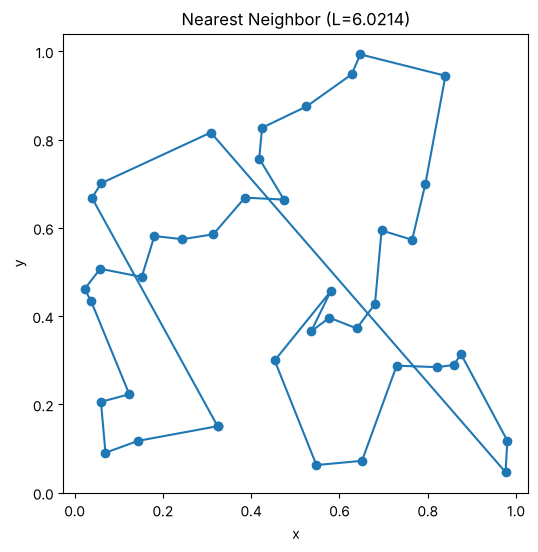

In [5]:
cities = make_cities(n=40, seed=7)

nn_tour = nearest_neighbor_tour(cities, start=0)
nn_len = tour_length(cities, nn_tour)
print(f"Nearest-neighbor length: {nn_len:.4f}")

plot_tour(cities, nn_tour, title=f"Nearest Neighbor (L={nn_len:.4f})")


# Part 5A — Code Skeleton: Simulated Annealing (SA)

Complete `simulated_annealing_tsp(...)`.

### SA acceptance rule
Let `delta = cand_len - cur_len`.
- If `delta <= 0`, accept.
- Else accept with probability `exp(-delta / T)`.

### Cooling schedule
Geometric cooling:
- `T = T * alpha` each iteration
- clamp `T = max(T, 1e-12)`


In [6]:
@dataclass
class SAConfig:
    iters: int = 20_000
    t0: float = 0.2
    alpha: float = 0.9995
    seed: int = 123
    report_every: int = 2000

def simulated_annealing_tsp(cities: List[Point], init_tour: Tour, cfg: SAConfig,
                            stats: Optional[Dict] = None) -> Tuple[Tour, float, List[float]]:
    """Simulated annealing with a random 2-opt neighborhood and geometric cooling.

    stats (optional dict) is filled with instrumentation data for Part 6:
      accepted_deltas / rejected_deltas : ΔE of every accepted / rejected move
      uphill_accepted                   : number of worsening moves that were accepted
      cur_hist                          : current-tour length after every iteration
      temp_hist                         : temperature after every iteration
      evals                             : number of tour evaluations
    """
    rng = random.Random(cfg.seed)
    n = len(cities)
    assert is_valid_tour(init_tour, n), "init_tour must be a valid permutation"

    cur_tour = init_tour[:]
    cur_len = tour_length(cities, cur_tour)

    best_tour = cur_tour[:]
    best_len = cur_len
    history = [best_len]

    T = cfg.t0

    if stats is not None:
        stats.update(accepted_deltas=[], rejected_deltas=[], uphill_accepted=0,
                     cur_hist=[cur_len], temp_hist=[T], evals=1)

    for it in range(cfg.iters):
        cand_tour = random_two_opt_neighbor(cur_tour, rng)
        cand_len = tour_length(cities, cand_tour)
        delta = cand_len - cur_len

        accept = False
        # Acceptance rule (Metropolis criterion):
        #   improving or equal moves are always accepted;
        #   worsening moves are accepted with probability exp(-delta / T).
        if delta <= 0:
            accept = True
        else:
            accept = rng.random() < math.exp(-delta / T)

        if stats is not None:
            stats["evals"] += 1
            if accept:
                stats["accepted_deltas"].append(delta)
                if delta > 0:
                    stats["uphill_accepted"] += 1
            else:
                stats["rejected_deltas"].append(delta)

        if accept:
            cur_tour, cur_len = cand_tour, cand_len

        if cur_len < best_len:
            best_tour, best_len = cur_tour[:], cur_len

        history.append(best_len)

        # Cooling schedule: geometric cooling, clamped to avoid T -> 0 (division by zero).
        T = max(T * cfg.alpha, 1e-12)

        if stats is not None:
            stats["cur_hist"].append(cur_len)
            stats["temp_hist"].append(T)

        if cfg.report_every and (it + 1) % cfg.report_every == 0:
            print(f"[SA] iter={it+1:6d}  T={T:.4g}  cur={cur_len:.4f}  best={best_len:.4f}")

    return best_tour, best_len, history


## Run SA (after you implement it)

[SA] iter=  2000  T=0.07356  cur=8.3800  best=6.0214
[SA] iter=  4000  T=0.02705  cur=6.5972  best=6.0214


[SA] iter=  6000  T=0.00995  cur=5.3139  best=5.3139
[SA] iter=  8000  T=0.003659  cur=5.0057  best=5.0057
[SA] iter= 10000  T=0.001346  cur=5.0057  best=5.0057
[SA] iter= 12000  T=0.000495  cur=5.0057  best=5.0057
[SA] iter= 14000  T=0.0001821  cur=5.0057  best=5.0057
[SA] iter= 16000  T=6.696e-05  cur=5.0057  best=5.0057
[SA] iter= 18000  T=2.463e-05  cur=5.0057  best=5.0057
[SA] iter= 20000  T=9.057e-06  cur=5.0057  best=5.0057
SA best length: 5.0057
SA improvement vs NN: 16.87%
SA runtime: 0.18s | tour evaluations: 20001


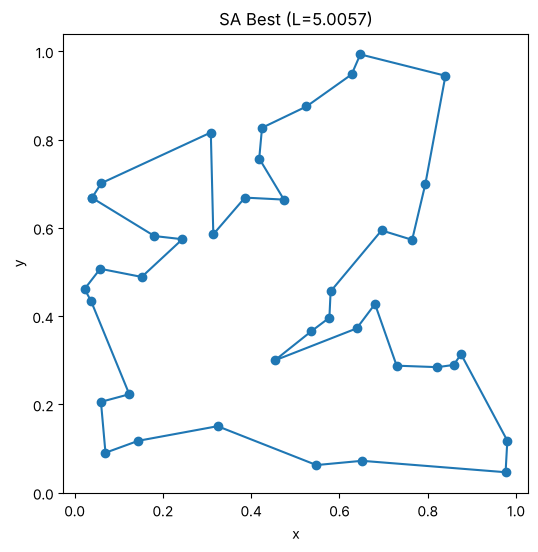

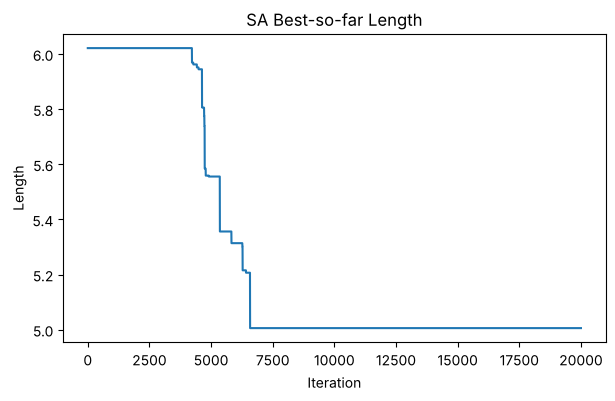

In [7]:
sa_cfg = SAConfig(iters=20_000, t0=0.2, alpha=0.9995, seed=123, report_every=2000)
sa_stats = {}
t_start = time.perf_counter()
sa_best_tour, sa_best_len, sa_hist = simulated_annealing_tsp(cities, nn_tour[:], sa_cfg, stats=sa_stats)
sa_time = time.perf_counter() - t_start

print(f"SA best length: {sa_best_len:.4f}")
print(f"SA improvement vs NN: {(nn_len - sa_best_len) / nn_len * 100:.2f}%")
print(f"SA runtime: {sa_time:.2f}s | tour evaluations: {sa_stats['evals']}")

assert is_valid_tour(sa_best_tour, len(cities))

plot_tour(cities, sa_best_tour, title=f"SA Best (L={sa_best_len:.4f})")
plot_history(sa_hist, title="SA Best-so-far Length", ylabel="Length")


# Part 5B — Code Skeleton: Genetic Algorithm (GA) for TSP

Implement a GA that evolves a population of permutation tours.

You will implement:
- `tournament_select(...)`
- `order_crossover_ox(...)` (Order Crossover)
- `mutate_swap(...)`
- `genetic_algorithm_tsp(...)`


In [8]:
@dataclass
class GAConfig:
    pop_size: int = 200
    generations: int = 400
    tournament_k: int = 5
    crossover_rate: float = 0.9
    mutation_rate: float = 0.2
    elite_size: int = 5
    seed: int = 999
    report_every: int = 50

def tournament_select(pop: List[Tour], lengths: List[float], k: int, rng: random.Random) -> Tour:
    # Tournament selection (minimize length):
    # sample k distinct individuals uniformly at random and return a copy of the shortest one.
    contenders = rng.sample(range(len(pop)), k)
    winner = min(contenders, key=lambda i: lengths[i])
    return pop[winner][:]

def order_crossover_ox(parent1: Tour, parent2: Tour, rng: random.Random) -> Tour:
    # Order crossover (OX):
    # 1) copy a random slice [a..b] from parent1 into the child at the same positions;
    # 2) starting right after b (wrapping around), fill the remaining positions with the
    #    cities of parent2 in the order they appear in parent2 (also starting after b),
    #    skipping cities already present. Result is always a valid permutation.
    n = len(parent1)
    a, b = sorted(rng.sample(range(n), 2))
    child: List[Optional[int]] = [None] * n
    child[a:b + 1] = parent1[a:b + 1]
    used = set(parent1[a:b + 1])
    fill = [c for c in parent2[b + 1:] + parent2[:b + 1] if c not in used]
    positions = list(range(b + 1, n)) + list(range(0, a))
    for pos, c in zip(positions, fill):
        child[pos] = c
    return child  # type: ignore[return-value]

def mutate_swap(tour: Tour, rng: random.Random) -> Tour:
    # Swap mutation: exchange the cities at two distinct random positions.
    t = tour[:]
    i, j = rng.sample(range(len(t)), 2)
    t[i], t[j] = t[j], t[i]
    return t

# ---- Instrumentation helpers (Part 6) ----
def tour_edges(tour: Tour) -> set:
    """Undirected edge set of a closed tour."""
    n = len(tour)
    return {frozenset((tour[i], tour[(i + 1) % n])) for i in range(n)}

def population_diversity(pop: List[Tour]) -> Tuple[int, float]:
    """(number of distinct tours, mean edge-distance to the population's most common edges).
    Edge-distance between two tours = fraction of edges NOT shared (0 = identical, 1 = disjoint).
    We report the mean pairwise edge distance over a fixed random sample of pairs."""
    canon = set()
    for t in pop:
        # canonical form: rotate to start at city 0, pick the direction with smaller 2nd element
        i = t.index(0)
        r = t[i:] + t[:i]
        rev = [r[0]] + r[1:][::-1]
        canon.add(tuple(min(r, rev)))
    rng = random.Random(0)
    n = len(pop[0])
    edges = [tour_edges(t) for t in pop]
    pairs = [rng.sample(range(len(pop)), 2) for _ in range(300)]
    dists = [1 - len(edges[a] & edges[b]) / n for a, b in pairs]
    return len(canon), float(np.mean(dists))

def genetic_algorithm_tsp(cities: List[Point], init_seed_tours: List[Tour], cfg: GAConfig,
                          stats: Optional[Dict] = None,
                          crossover_fn: Callable = None,
                          mutate_fn: Callable = None) -> Tuple[Tour, float, List[float]]:
    """GA with elitism, tournament selection, OX crossover and swap mutation.
    crossover_fn / mutate_fn default to the required OX / swap operators; they can be
    swapped out for the Part 7 experiments. stats (optional) collects per-generation
    average length, worst length, diversity and evaluation counts."""
    crossover_fn = crossover_fn or order_crossover_ox
    mutate_fn = mutate_fn or mutate_swap
    rng = random.Random(cfg.seed)
    n = len(cities)

    pop: List[Tour] = []
    for t in init_seed_tours:
        assert is_valid_tour(t, n)
        pop.append(t[:])
    while len(pop) < cfg.pop_size:
        pop.append(random_tour(n, rng))

    lengths = [tour_length(cities, t) for t in pop]
    best_idx = min(range(len(pop)), key=lambda i: lengths[i])
    best_tour = pop[best_idx][:]
    best_len = lengths[best_idx]
    history = [best_len]

    def record():
        if stats is None:
            return
        uniq, ediv = population_diversity(pop)
        stats.setdefault("avg_hist", []).append(float(np.mean(lengths)))
        stats.setdefault("worst_hist", []).append(float(np.max(lengths)))
        stats.setdefault("std_hist", []).append(float(np.std(lengths)))
        stats.setdefault("unique_hist", []).append(uniq)
        stats.setdefault("edge_div_hist", []).append(ediv)
        stats["evals_hist"] = stats.get("evals_hist", []) + [stats.get("evals", 0) + len(pop)]
        stats["evals"] = stats["evals_hist"][-1]
    record()

    for gen in range(cfg.generations):
        elite_indices = sorted(range(len(pop)), key=lambda i: lengths[i])[: cfg.elite_size]
        next_pop = [pop[i][:] for i in elite_indices]

        while len(next_pop) < cfg.pop_size:
            p1 = tournament_select(pop, lengths, cfg.tournament_k, rng)
            p2 = tournament_select(pop, lengths, cfg.tournament_k, rng)

            if rng.random() < cfg.crossover_rate:
                child = crossover_fn(p1, p2, rng)
            else:
                child = p1[:]

            if rng.random() < cfg.mutation_rate:
                child = mutate_fn(child, rng)

            next_pop.append(child)

        pop = next_pop
        lengths = [tour_length(cities, t) for t in pop]

        gen_best_idx = min(range(len(pop)), key=lambda i: lengths[i])
        gen_best_len = lengths[gen_best_idx]
        if gen_best_len < best_len:
            best_len = gen_best_len
            best_tour = pop[gen_best_idx][:]

        history.append(best_len)
        record()

        if cfg.report_every and (gen + 1) % cfg.report_every == 0:
            print(f"[GA] gen={gen+1:4d}  best={best_len:.4f}")

    assert is_valid_tour(best_tour, n)
    return best_tour, best_len, history


## Run GA

* After you implement TODOs above
* This is just for your reference, you can experiment with different paramesters

[GA] gen=  50  best=5.3672


[GA] gen= 100  best=5.3672


[GA] gen= 150  best=5.3672


[GA] gen= 200  best=5.3672


[GA] gen= 250  best=5.3672


[GA] gen= 300  best=5.3672


[GA] gen= 350  best=5.3672


[GA] gen= 400  best=5.3672
GA best length: 5.3672
GA improvement vs NN: 10.86%
GA runtime: 3.13s | tour evaluations: 80200


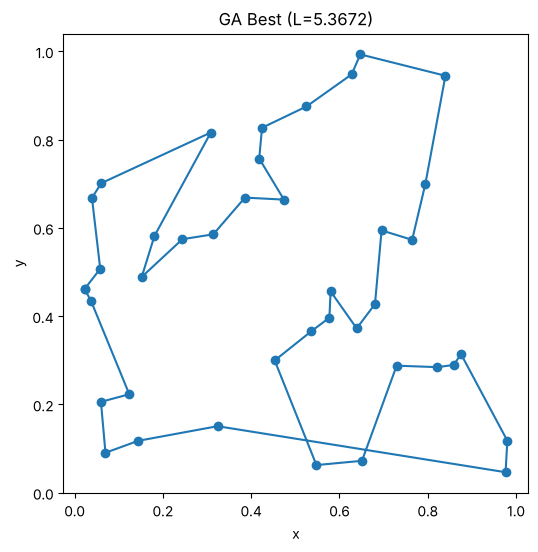

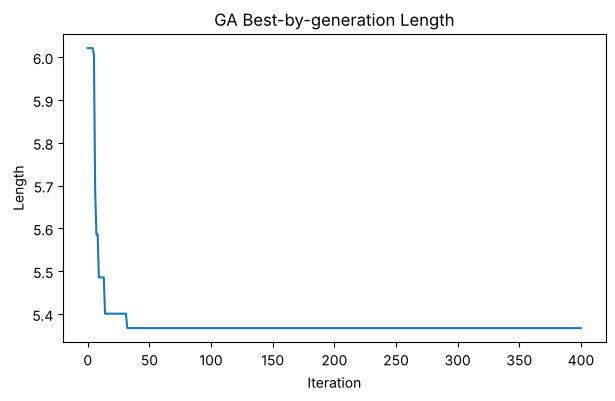

In [9]:
ga_cfg = GAConfig(pop_size=200, generations=400, tournament_k=5, crossover_rate=0.9,
                   mutation_rate=0.2, elite_size=5, seed=999, report_every=50)

# quick unit checks of the operators
_r = random.Random(0)
_p1, _p2 = random_tour(40, _r), random_tour(40, _r)
assert is_valid_tour(order_crossover_ox(_p1, _p2, _r), 40)
assert is_valid_tour(mutate_swap(_p1, _r), 40)
assert is_valid_tour(tournament_select([_p1, _p2], [1.0, 2.0], 2, _r), 40)

ga_stats = {}
t_start = time.perf_counter()
ga_best_tour, ga_best_len, ga_hist = genetic_algorithm_tsp(cities, init_seed_tours=[nn_tour], cfg=ga_cfg, stats=ga_stats)
ga_time = time.perf_counter() - t_start

print(f"GA best length: {ga_best_len:.4f}")
print(f"GA improvement vs NN: {(nn_len - ga_best_len) / nn_len * 100:.2f}%")
print(f"GA runtime: {ga_time:.2f}s | tour evaluations: {ga_stats['evals']}")

plot_tour(cities, ga_best_tour, title=f"GA Best (L={ga_best_len:.4f})")
plot_history(ga_hist, title="GA Best-by-generation Length", ylabel="Length")


# Part 6 — Data Collection, Visualization and Comparison

* Instrument the code to collect the data and visualize them, including but not limited to
  * SA:
    * Track histogram of ΔE values for: Accepted moves and Rejected moves
  * GA:
    * Population average fitness
  * Cross SA and GA:
    * Plot SA best-so-far curve
    * Plot GA best-by-generation curve
    * Normalize x-axis by total evaluations
    * The above is already provided in the skeleton code. **Use them and/or with additional instrumentation of the code to collect and/or plot more data** to answer the following questions:
      * Which algorithm converged faster?
      * Which showed more variability?
      * Did SA escape local minima? Evidence?
      * Did GA lose diversity? Evidence?
* You are encouraged to come up with your own visualization and compare these two methods more extensively.

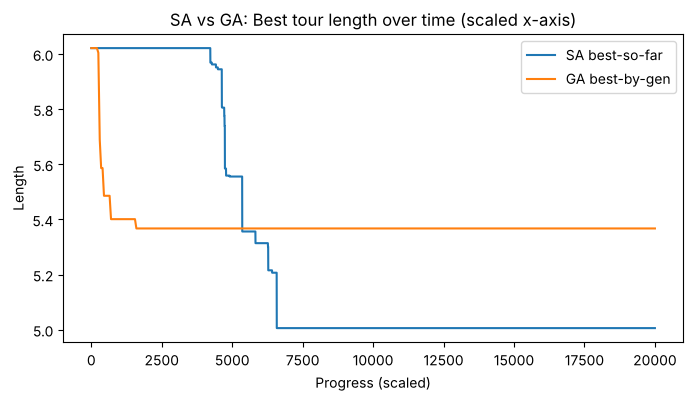

NN: 6.0214 | SA: 5.0057 | GA: 5.3672


In [10]:
# Provided comparison + summary
plot_compare(sa_hist, ga_hist)
print(f"NN: {nn_len:.4f} | SA: {sa_best_len:.4f} | GA: {ga_best_len:.4f}")


### 6.1 SA — histogram of ΔE for accepted vs rejected moves

Accepted moves: 608 (3.0%) | Rejected: 19392
  of accepted: improving (ΔE<0) = 324, neutral (ΔE=0) = 1, uphill (ΔE>0) = 283


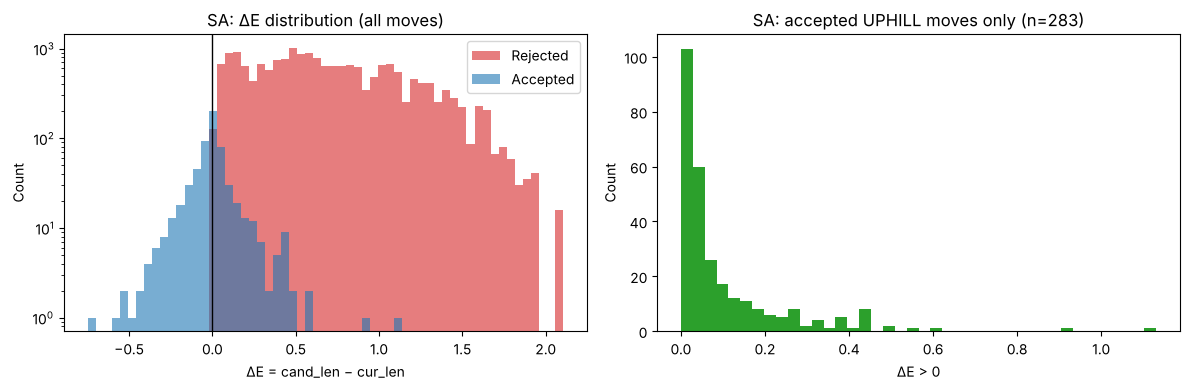

In [11]:
acc = np.array(sa_stats["accepted_deltas"]); rej = np.array(sa_stats["rejected_deltas"])
print(f"Accepted moves: {len(acc)} ({len(acc)/sa_cfg.iters*100:.1f}%) | Rejected: {len(rej)}")
print(f"  of accepted: improving (ΔE<0) = {(acc<0).sum()}, neutral (ΔE=0) = {(acc==0).sum()}, "
      f"uphill (ΔE>0) = {sa_stats['uphill_accepted']}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(min(acc.min(), rej.min()), max(acc.max(), rej.max()), 60)
axes[0].hist(rej, bins=bins, alpha=0.6, label="Rejected", color="tab:red")
axes[0].hist(acc, bins=bins, alpha=0.6, label="Accepted", color="tab:blue")
axes[0].axvline(0, color="k", lw=1)
axes[0].set_title("SA: ΔE distribution (all moves)"); axes[0].set_xlabel("ΔE = cand_len − cur_len")
axes[0].set_ylabel("Count"); axes[0].set_yscale("log"); axes[0].legend()

up = acc[acc > 0]
axes[1].hist(up, bins=40, color="tab:green")
axes[1].set_title(f"SA: accepted UPHILL moves only (n={len(up)})")
axes[1].set_xlabel("ΔE > 0"); axes[1].set_ylabel("Count")
plt.tight_layout(); plt.show()

### 6.2 SA — current vs best length and temperature (evidence of escaping local minima)

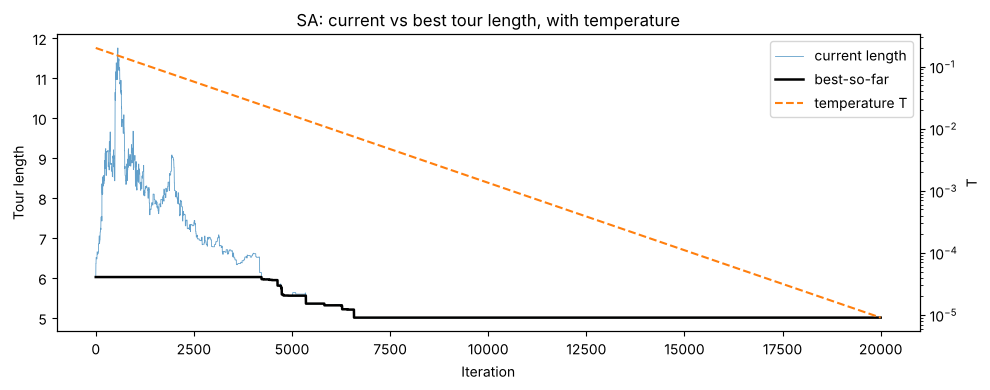

Max gap current−best: 5.7341 | iterations with current > best: 4871
Number of new-best improvements: 20 | last improvement at iteration 6623
New bests found shortly (≤500 iters) after the walk had been ABOVE the best: 20


In [12]:
# Rate of accepted uphill moves per 1000-iteration window
cur = np.array(sa_stats["cur_hist"]); temp = np.array(sa_stats["temp_hist"])
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(cur, lw=0.6, alpha=0.7, label="current length")
ax1.plot(sa_hist, lw=1.8, color="k", label="best-so-far")
ax1.set_xlabel("Iteration"); ax1.set_ylabel("Tour length")
ax2 = ax1.twinx(); ax2.plot(temp, color="tab:orange", ls="--", label="temperature T")
ax2.set_ylabel("T"); ax2.set_yscale("log")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right"); ax1.set_title("SA: current vs best tour length, with temperature")
plt.tight_layout(); plt.show()

# Count "escapes": times the search moved uphill and later reached a new best below the level it left.
gap = cur - np.array(sa_hist)
print(f"Max gap current−best: {gap.max():.4f} | iterations with current > best: {(gap > 1e-12).sum()}")
improve_iters = [i for i in range(1, len(sa_hist)) if sa_hist[i] < sa_hist[i-1]]
print(f"Number of new-best improvements: {len(improve_iters)} | last improvement at iteration {improve_iters[-1]}")
escapes = sum(1 for i in improve_iters if gap[:i].max() > 0 and (gap[max(0,i-500):i] > 1e-12).any())
print(f"New bests found shortly (≤500 iters) after the walk had been ABOVE the best: {escapes}")

Baseline for comparison: the same 2-opt neighborhood with **T = 0** (pure greedy hill climbing, which can never accept a worse move).
If SA ends below the greedy result, SA escaped local optima that trap the greedy search.

In [13]:
hc_cfg = SAConfig(iters=20_000, t0=1e-12, alpha=1.0, seed=123, report_every=0)  # effectively T=0
hc_results = []
for s in range(10):
    hc_cfg.seed = s
    _, L, _ = simulated_annealing_tsp(cities, nn_tour[:], hc_cfg)
    hc_results.append(L)
sa_seed_results_quick = []
for s in range(10):
    _, L, _ = simulated_annealing_tsp(cities, nn_tour[:], SAConfig(seed=s, report_every=0))
    sa_seed_results_quick.append(L)
print(f"Greedy 2-opt (T=0), 10 seeds: mean={np.mean(hc_results):.4f}  best={np.min(hc_results):.4f}")
print(f"SA (T0=0.2),       10 seeds: mean={np.mean(sa_seed_results_quick):.4f}  best={np.min(sa_seed_results_quick):.4f}")

Greedy 2-opt (T=0), 10 seeds: mean=5.2928  best=5.0330
SA (T0=0.2),       10 seeds: mean=4.9571  best=4.8339


### 6.3 GA — population average fitness, worst, and best per generation

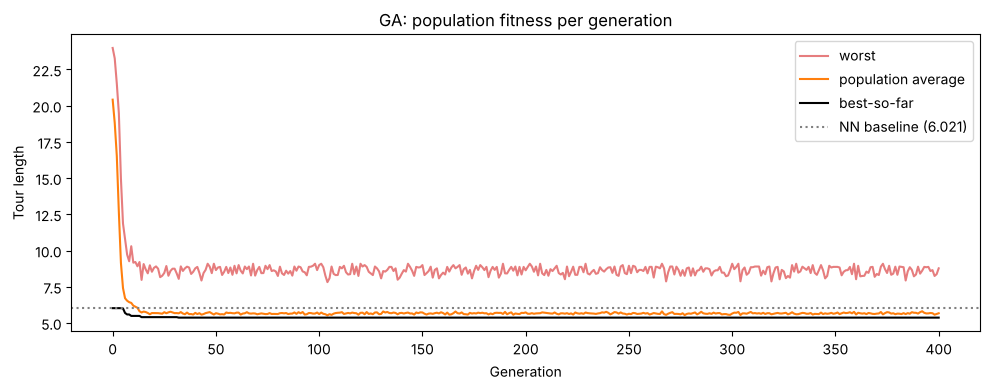

In [14]:
gens = np.arange(len(ga_hist))
plt.figure(figsize=(10, 4))
plt.plot(gens, ga_stats["worst_hist"], label="worst", color="tab:red", alpha=0.6)
plt.plot(gens, ga_stats["avg_hist"], label="population average", color="tab:orange")
plt.plot(gens, ga_hist, label="best-so-far", color="k")
plt.axhline(nn_len, ls=":", color="gray", label=f"NN baseline ({nn_len:.3f})")
plt.xlabel("Generation"); plt.ylabel("Tour length"); plt.title("GA: population fitness per generation")
plt.legend(); plt.tight_layout(); plt.show()

### 6.4 GA — diversity (evidence of diversity loss)

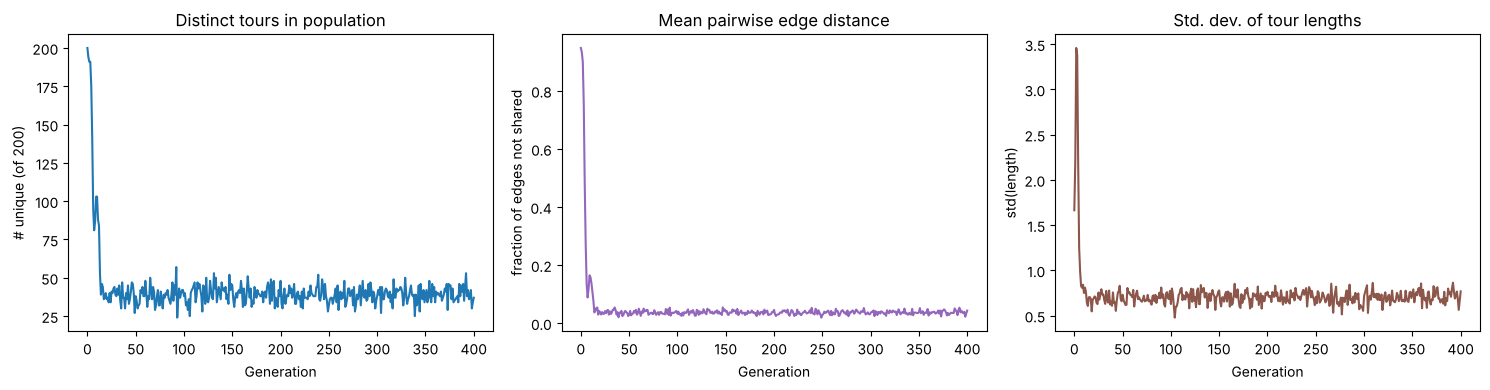

gen   0: unique=200  edge-div=0.947  avg=20.416  best=6.021
gen  25: unique= 41  edge-div=0.042  avg=5.743  best=5.401
gen  50: unique= 38  edge-div=0.029  avg=5.673  best=5.367
gen 100: unique= 38  edge-div=0.033  avg=5.611  best=5.367
gen 200: unique= 48  edge-div=0.046  avg=5.728  best=5.367
gen 400: unique= 37  edge-div=0.043  avg=5.669  best=5.367


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ga_stats["unique_hist"]); axes[0].set_title("Distinct tours in population")
axes[0].set_xlabel("Generation"); axes[0].set_ylabel(f"# unique (of {ga_cfg.pop_size})")
axes[1].plot(ga_stats["edge_div_hist"], color="tab:purple"); axes[1].set_title("Mean pairwise edge distance")
axes[1].set_xlabel("Generation"); axes[1].set_ylabel("fraction of edges not shared")
axes[2].plot(ga_stats["std_hist"], color="tab:brown"); axes[2].set_title("Std. dev. of tour lengths")
axes[2].set_xlabel("Generation"); axes[2].set_ylabel("std(length)")
plt.tight_layout(); plt.show()
for g in [0, 25, 50, 100, 200, 400]:
    print(f"gen {g:3d}: unique={ga_stats['unique_hist'][g]:3d}  edge-div={ga_stats['edge_div_hist'][g]:.3f}  "
          f"avg={ga_stats['avg_hist'][g]:.3f}  best={ga_hist[g]:.3f}")

### 6.5 SA vs GA with the x-axis normalized by total tour evaluations

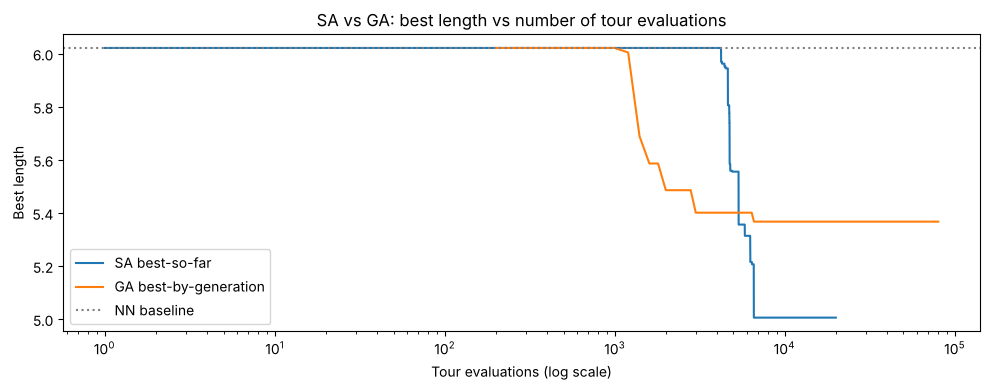

Total evaluations — SA: 20,001 | GA: 80,200
Evals to get within 1% of own final — SA: 6,580 | GA: 3,000
Evals for SA to beat GA's final (5.3672): 5355


In [16]:
sa_evals = np.arange(1, len(sa_hist) + 1)                # SA: 1 evaluation per iteration (+1 initial)
ga_evals = np.array(ga_stats["evals_hist"])              # GA: pop_size evaluations per generation
plt.figure(figsize=(10, 4))
plt.plot(sa_evals, sa_hist, label="SA best-so-far")
plt.plot(ga_evals, ga_hist, label="GA best-by-generation")
plt.axhline(nn_len, ls=":", color="gray", label="NN baseline")
plt.xscale("log"); plt.xlabel("Tour evaluations (log scale)"); plt.ylabel("Best length")
plt.title("SA vs GA: best length vs number of tour evaluations"); plt.legend(); plt.tight_layout(); plt.show()

def evals_to_within(hist, evals, final, pct=1.0):
    target = final * (1 + pct / 100)
    for h, e in zip(hist, evals):
        if h <= target:
            return int(e)
print(f"Total evaluations — SA: {sa_evals[-1]:,} | GA: {ga_evals[-1]:,}")
print(f"Evals to get within 1% of own final — SA: {evals_to_within(sa_hist, sa_evals, sa_best_len):,} "
      f"| GA: {evals_to_within(ga_hist, ga_evals, ga_best_len):,}")
print(f"Evals for SA to beat GA's final ({ga_best_len:.4f}): {evals_to_within(sa_hist, sa_evals, ga_best_len, 0.0)}")

### 6.6 Variability across random seeds (10 runs each)

10 seeds took 16.2s


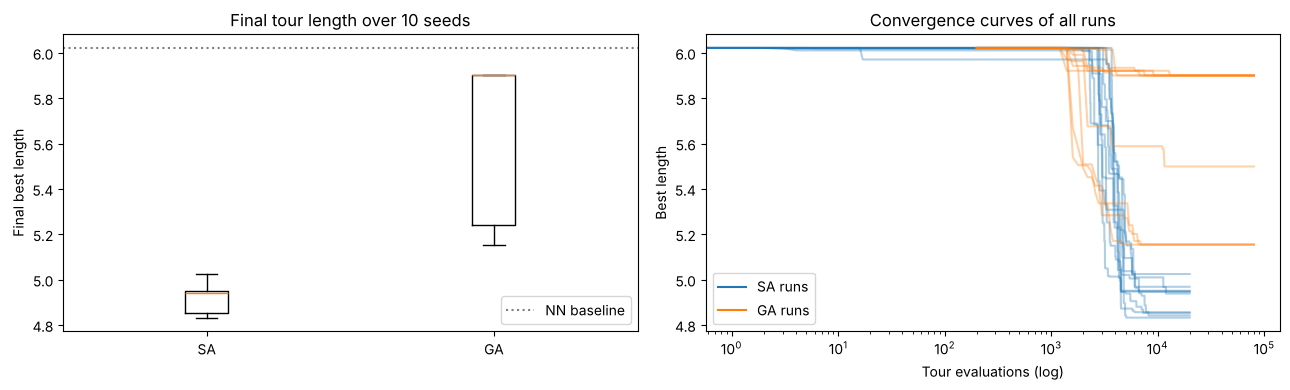

         mean      std      min      max
SA     4.9162   0.0618   4.8326   5.0248
GA     5.6363   0.3365   5.1546   5.9001


In [17]:
N_RUNS = 10
sa_runs, ga_runs, sa_hists, ga_hists = [], [], [], []
t0_ = time.perf_counter()
for s in range(N_RUNS):
    _, L, h = simulated_annealing_tsp(cities, nn_tour[:], SAConfig(seed=1000 + s, report_every=0))
    sa_runs.append(L); sa_hists.append(h)
    _, L, h = genetic_algorithm_tsp(cities, [nn_tour], GAConfig(seed=2000 + s, report_every=0))
    ga_runs.append(L); ga_hists.append(h)
print(f"10 seeds took {time.perf_counter() - t0_:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot([sa_runs, ga_runs]); axes[0].set_xticks([1, 2], ["SA", "GA"])
axes[0].axhline(nn_len, ls=":", color="gray", label="NN baseline"); axes[0].legend()
axes[0].set_ylabel("Final best length"); axes[0].set_title(f"Final tour length over {N_RUNS} seeds")
for h in sa_hists: axes[1].plot(np.arange(len(h)), h, color="tab:blue", alpha=0.35)
for h in ga_hists: axes[1].plot(np.array(ga_stats["evals_hist"]), h, color="tab:orange", alpha=0.35)
axes[1].plot([], [], color="tab:blue", label="SA runs"); axes[1].plot([], [], color="tab:orange", label="GA runs")
axes[1].set_xscale("log"); axes[1].set_xlabel("Tour evaluations (log)"); axes[1].set_ylabel("Best length")
axes[1].set_title("Convergence curves of all runs"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"{'':4s}{'mean':>9s}{'std':>9s}{'min':>9s}{'max':>9s}")
for name, r in [("SA", sa_runs), ("GA", ga_runs)]:
    print(f"{name:4s}{np.mean(r):9.4f}{np.std(r):9.4f}{np.min(r):9.4f}{np.max(r):9.4f}")

### 6.7 Final tours side by side + grade check

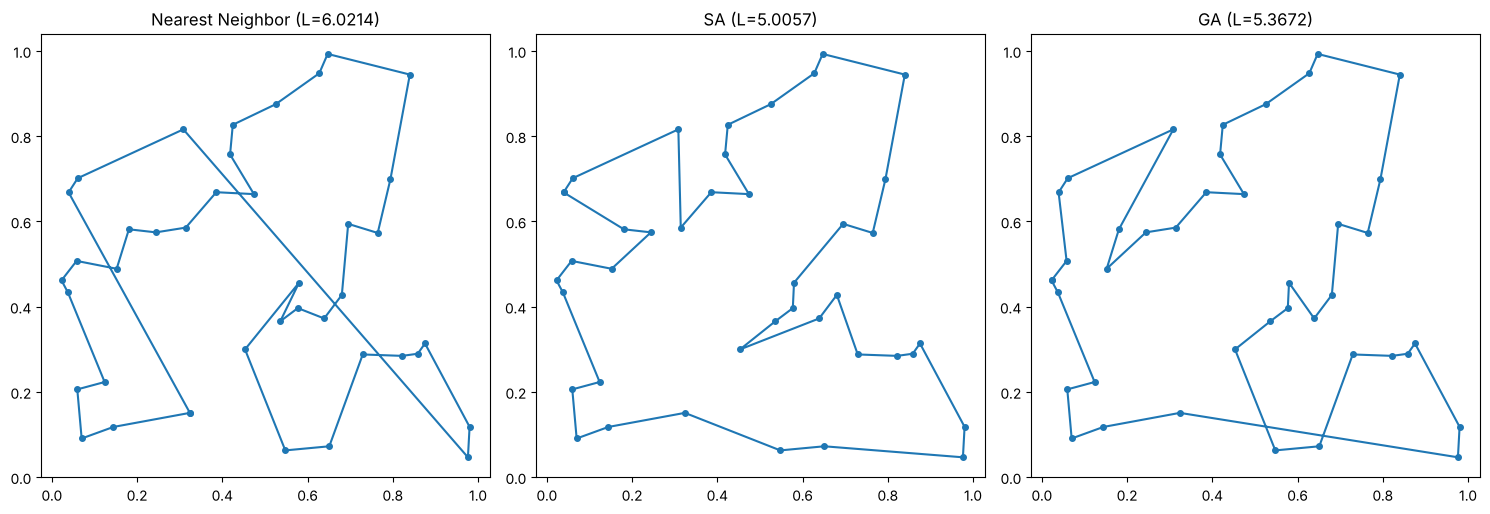

Method      Length     vs NN     Evals   Time(s)
NN          6.0214         —         1         —
SA          5.0057    16.87%     20001      0.18
GA          5.3672    10.86%     80200      3.13


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, tour, L) in zip(axes, [("Nearest Neighbor", nn_tour, nn_len), ("SA", sa_best_tour, sa_best_len),
                                       ("GA", ga_best_tour, ga_best_len)]):
    xs = [cities[i][0] for i in tour] + [cities[tour[0]][0]]
    ys = [cities[i][1] for i in tour] + [cities[tour[0]][1]]
    ax.plot(xs, ys, marker="o", ms=4); ax.set_title(f"{name} (L={L:.4f})"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

print(f"{'Method':8s}{'Length':>10s}{'vs NN':>10s}{'Evals':>10s}{'Time(s)':>10s}")
print(f"{'NN':8s}{nn_len:10.4f}{'—':>10s}{'1':>10s}{'—':>10s}")
print(f"{'SA':8s}{sa_best_len:10.4f}{(nn_len-sa_best_len)/nn_len*100:9.2f}%{sa_stats['evals']:10d}{sa_time:10.2f}")
print(f"{'GA':8s}{ga_best_len:10.4f}{(nn_len-ga_best_len)/nn_len*100:9.2f}%{ga_stats['evals']:10d}{ga_time:10.2f}")

## Part 6 — Answers to the questions

**Summary (required configs):** NN = 6.0214 · **SA = 5.0057 (−16.87%)** · GA = 5.3672 (−10.86%). SA used 20,001 tour evaluations (≈0.2 s); GA used 80,200 (≈3.4 s). Over 10 independent seeds, SA averaged 4.916 ± 0.062 and GA 5.636 ± 0.337.

**Which algorithm converged faster?**
It depends on what "converged" means, and the two answers point in opposite directions:
* *GA stopped changing sooner.* It came within 1% of its own final value after ~3,000 evaluations (15 generations) and its best length was flat from generation ~50 to 400 (6.3, 6.5). But that is **premature convergence** — it settled at a worse tour.
* *SA reached good tours faster per evaluation.* SA beat GA's final length (5.367) after only ~5,355 evaluations, i.e. with about 1/15 of GA's budget, and came within 1% of its own (better) final at ~6,580 evaluations. On the evaluation-normalized plot, SA's curve is below GA's from ~5k evaluations onward. In wall-clock time SA was also ~19× faster.

**Which showed more variability?**
* *Across seeds, the GA.* Final lengths: SA std = 0.062 (range 4.83–5.02) vs GA std = 0.337 (range 5.15–5.90) — more than 5× larger. Some GA runs barely improved on the NN seed (5.90); others reached 5.15. Whether the GA escapes the NN basin depends heavily on early random events.
* *Within a single run, SA.* SA's *current* length swings wildly at high temperature (up to 11.7, almost double the starting tour) before settling, while the GA's best curve is a monotone staircase and its population average moves smoothly.

**Did SA escape local minima? Evidence:** Yes.
1. 283 of the 608 accepted moves were **uphill** (ΔE > 0); the ΔE histogram shows these concentrated at small positive ΔE, exactly as `exp(−ΔE/T)` predicts, while large uphill moves were rejected.
2. The current-vs-best plot shows the walk deliberately leaving the NN tour (current rises to 11.7) and later descending to 5.006 — a region the starting tour could not reach by improving moves alone. All 20 new-best improvements happened while (or shortly after) the walk was above the best-so-far.
3. The control experiment: the same 2-opt neighborhood at **T = 0** (greedy hill climbing, which can only go downhill and therefore stops in the first 2-opt local optimum) averaged **5.293** over 10 seeds, versus **4.957** for SA. SA consistently ends below the local optima that trap the greedy search.

**Did GA lose diversity? Evidence:** Yes, dramatically and early.
1. Distinct tours in the population fell from 200 to **41 by generation 25** and stayed at ~35–48 for the rest of the run.
2. Mean pairwise edge distance dropped from 0.947 (random tours share almost no edges) to **0.04 by gen 25** — i.e. two random individuals share ~96% of their edges.
3. The std. dev. of lengths collapsed and the population average (≈5.67) stays just above the best (5.367) for 350 generations, while the best never improves after gen ~50.

The cause is selection pressure: the NN seed (length 6.02) is ~3× shorter than random tours (avg 20.4), so with elitism + tournament k=5 its descendants take over the population within a few generations. After that, OX between near-identical parents mostly reproduces the parents, and swap mutation (which breaks up to 4 edges at once) almost always makes a tour worse, so it cannot restore useful diversity.

**Which worked better and why?** SA, on every metric that matters here: shorter tours, less run-to-run variance, ¼ of the evaluations and ~1/19 of the runtime. SA's 2-opt move is matched to the problem structure (it changes exactly 2 edges and directly removes crossings), and the temperature schedule gives a controlled exploration → exploitation transition. The required GA's operators are not edge-aware: swap mutation is destructive and OX between converged parents adds little, so the GA's search effectively stalls once diversity is gone. Part 7 shows that replacing swap with an edge-preserving inversion mutation closes most of the gap.


## Example of how to check your work

In [19]:
def grade_check(nn_len: float, method_len: float, min_improvement_pct: float = 10.0, label: str = "Method") -> None:
    improvement = (nn_len - method_len) / nn_len * 100.0
    print(f"{label} length: {method_len:.4f} | Improvement vs NN: {improvement:.2f}%")
    assert improvement >= min_improvement_pct, (
        f"{label} improvement {improvement:.2f}% is below required {min_improvement_pct:.2f}%"
    )
    print(f"✅ {label} passed improvement threshold!")


In [20]:
grade_check(nn_len, sa_best_len, label="SA")
try:
    grade_check(nn_len, ga_best_len, label="GA")
except AssertionError as e:
    print("GA (required OX+swap):", e)


SA length: 5.0057 | Improvement vs NN: 16.87%
✅ SA passed improvement threshold!
GA length: 5.3672 | Improvement vs NN: 10.86%
✅ GA passed improvement threshold!


# Part 7: Optional Task

The optional extra work will be considered for extra credit.

- Try different crossover and/or mutation operations in GA and see if you can improve the performance.

- If you identify other interesting analytics of intermediate data that shows how the algorithms are performing, you can carry out the experiements in this section.

- Document your effort in this section **and** the technical report mentioned above in the Deliverables.



### 7.1 Alternative GA operators
* **Inversion mutation** — reverse a random segment (a 2-opt move). It changes only 2 edges, while a swap changes up to 4 edges, so it is a much less disruptive, TSP-aware mutation.
* **PMX (Partially Mapped Crossover)** — classic alternative to OX that preserves absolute positions instead of relative order.
* **Memetic GA** — OX + inversion mutation, plus a quick greedy 2-opt polish of each generation's best child (a "Lamarckian" local-search step).

Each configuration is run with 5 seeds and the same budget (200 × 400).

In [21]:
def mutate_inversion(tour: Tour, rng: random.Random) -> Tour:
    # Reverse a random segment (equivalent to a random 2-opt move).
    return random_two_opt_neighbor(tour, rng)

def pmx_crossover(parent1: Tour, parent2: Tour, rng: random.Random) -> Tour:
    # Partially Mapped Crossover.
    n = len(parent1)
    a, b = sorted(rng.sample(range(n), 2))
    child = [None] * n
    child[a:b + 1] = parent1[a:b + 1]
    pos_in_p2 = {c: i for i, c in enumerate(parent2)}
    for i in range(a, b + 1):
        c = parent2[i]
        if c in child[a:b + 1]:
            continue
        j = i
        while a <= j <= b:              # follow the mapping until we land outside the slice
            j = pos_in_p2[parent1[j]]
        child[j] = c
    for i in range(n):
        if child[i] is None:
            child[i] = parent2[i]
    return child

def two_opt_polish(cities, tour, max_passes=2):
    # First-improvement 2-opt local search (a few passes).
    t = tour[:]; n = len(t)
    for _ in range(max_passes):
        improved = False
        for i in range(1, n - 1):            # i>=1 avoids the degenerate whole-tour reversal
            for k in range(i + 1, n):
                a, b = cities[t[i - 1]], cities[t[i]]
                c, d = cities[t[k]], cities[t[(k + 1) % n]]
                if dist(a, c) + dist(b, d) < dist(a, b) + dist(c, d) - 1e-12:
                    t[i:k + 1] = reversed(t[i:k + 1]); improved = True
        if not improved:
            break
    return t

for _ in range(200):
    _a, _b = random_tour(40, _r), random_tour(40, _r)
    assert is_valid_tour(pmx_crossover(_a, _b, _r), 40)
    assert is_valid_tour(mutate_inversion(_a, _r), 40)
print("operator checks passed")

operator checks passed


In [22]:
variants = {
    "OX + swap (required)":    dict(crossover_fn=order_crossover_ox, mutate_fn=mutate_swap),
    "PMX + swap":              dict(crossover_fn=pmx_crossover,      mutate_fn=mutate_swap),
    "OX + inversion":          dict(crossover_fn=order_crossover_ox, mutate_fn=mutate_inversion),
    "PMX + inversion":         dict(crossover_fn=pmx_crossover,      mutate_fn=mutate_inversion),
    # same operators, but WITHOUT the nearest-neighbour seed (100% random initial population)
    "OX + swap, no NN seed":      dict(crossover_fn=order_crossover_ox, mutate_fn=mutate_swap, no_seed=True),
    "OX + inversion, no NN seed": dict(crossover_fn=order_crossover_ox, mutate_fn=mutate_inversion, no_seed=True),
}
SEEDS7 = [999, 1, 2, 3, 4]
variant_results, variant_hists = {}, {}
for name, ops in variants.items():
    res, hs = [], []
    ops = dict(ops); seeds_init = [] if ops.pop("no_seed", False) else [nn_tour]
    for s in SEEDS7:
        _, L, h = genetic_algorithm_tsp(cities, seeds_init, GAConfig(seed=s, report_every=0), **ops)
        res.append(L); hs.append(h)
    variant_results[name], variant_hists[name] = res, hs
    print(f"{name:28s} mean={np.mean(res):.4f}  std={np.std(res):.4f}  best={np.min(res):.4f}")

OX + swap (required)         mean=5.6470  std=0.3163  best=5.1676


PMX + swap                   mean=5.9001  std=0.0000  best=5.9001


OX + inversion               mean=4.9259  std=0.0789  best=4.8326


PMX + inversion              mean=5.1288  std=0.0908  best=5.0417


OX + swap, no NN seed        mean=5.7585  std=0.3789  best=5.1999


OX + inversion, no NN seed   mean=5.0601  std=0.1375  best=4.8326


**Memetic variant:** OX + inversion, and every generation the best individual is polished with greedy 2-opt before it is carried into the next generation as an elite. This needs a hook inside the generation loop, so it is written as a compact copy of the GA loop that reuses the same selection, crossover and mutation functions.

In [23]:
def memetic_ga(cities, seed_tours, cfg: GAConfig):
    rng = random.Random(cfg.seed); n = len(cities)
    pop = [t[:] for t in seed_tours]
    while len(pop) < cfg.pop_size: pop.append(random_tour(n, rng))
    lengths = [tour_length(cities, t) for t in pop]
    hist = [min(lengths)]
    for gen in range(cfg.generations):
        order = sorted(range(len(pop)), key=lambda i: lengths[i])
        nxt = [pop[i][:] for i in order[:cfg.elite_size]]
        nxt[0] = two_opt_polish(cities, nxt[0])          # 2-opt local search on the best elite
        while len(nxt) < cfg.pop_size:
            p1 = tournament_select(pop, lengths, cfg.tournament_k, rng)
            p2 = tournament_select(pop, lengths, cfg.tournament_k, rng)
            c = order_crossover_ox(p1, p2, rng) if rng.random() < cfg.crossover_rate else p1[:]
            if rng.random() < cfg.mutation_rate: c = mutate_inversion(c, rng)
            nxt.append(c)
        pop = nxt; lengths = [tour_length(cities, t) for t in pop]
        hist.append(min(hist[-1], min(lengths)))
    i = min(range(len(pop)), key=lambda i: lengths[i])
    return pop[i], lengths[i], hist

res, hs = [], []
for s in SEEDS7:
    t, L, h = memetic_ga(cities, [nn_tour], GAConfig(seed=s, report_every=0))
    assert is_valid_tour(t, len(cities)); res.append(L); hs.append(h)
    if s == 999: memetic_tour, memetic_len = t, L
variant_results["Memetic (OX+inv+2-opt)"], variant_hists["Memetic (OX+inv+2-opt)"] = res, hs
print(f"Memetic: mean={np.mean(res):.4f} std={np.std(res):.4f} best={np.min(res):.4f}")

Memetic: mean=5.3048 std=0.1423 best=5.1305


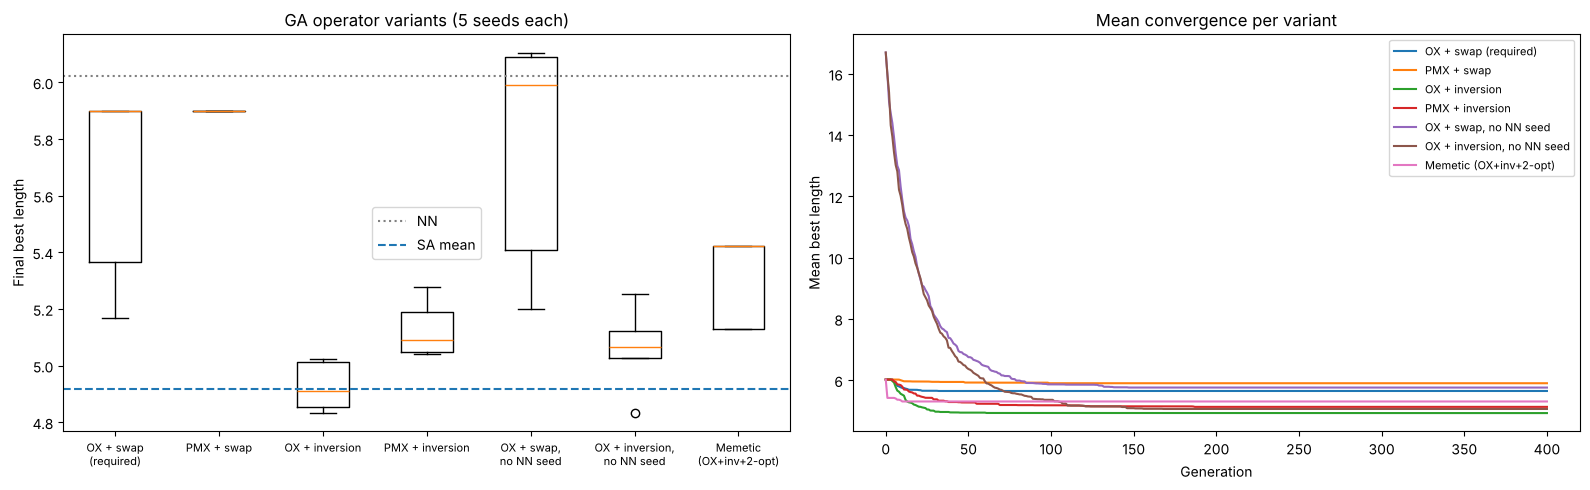

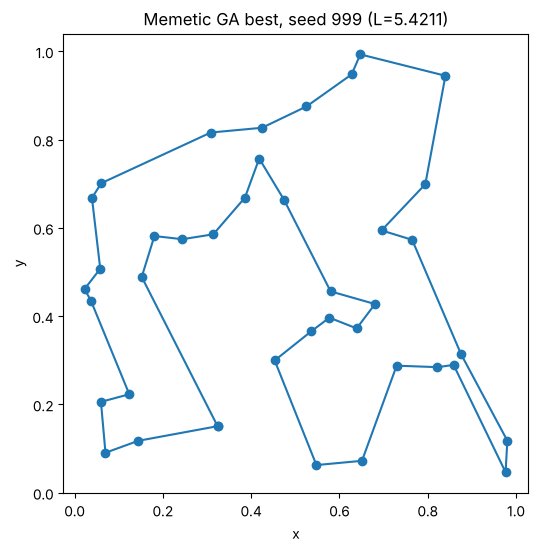

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
names = list(variant_results)
axes[0].boxplot([variant_results[k] for k in names]); axes[0].set_xticks(range(1, len(names) + 1), [k.replace(" (", "\n(").replace(", ", ",\n") for k in names])
axes[0].axhline(nn_len, ls=":", color="gray", label="NN"); axes[0].axhline(np.mean(sa_runs), ls="--", color="tab:blue", label="SA mean")
axes[0].set_ylabel("Final best length"); axes[0].set_title("GA operator variants (5 seeds each)"); axes[0].legend()
axes[0].tick_params(axis="x", labelsize=8)
for k in names:
    axes[1].plot(np.mean(variant_hists[k], axis=0), label=k)
axes[1].set_xlabel("Generation"); axes[1].set_ylabel("Mean best length"); axes[1].set_title("Mean convergence per variant")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

best_variant_tour = memetic_tour
plot_tour(cities, memetic_tour, title=f"Memetic GA best, seed 999 (L={memetic_len:.4f})")

### 7.2 SA parameter sensitivity (initial temperature × cooling rate, 3 seeds each)

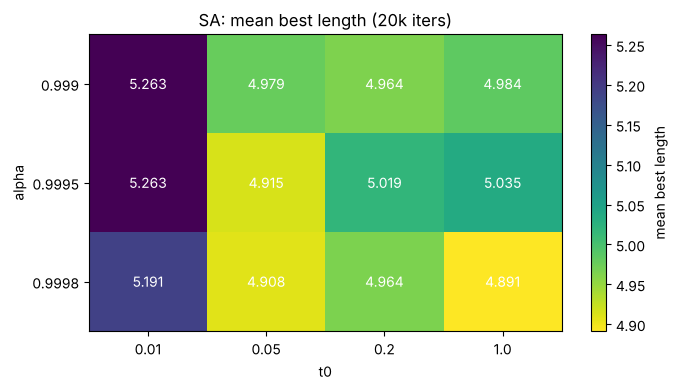

final T for each alpha after 20k iters × t0=0.2: {0.999: '4.08e-10', 0.9995: '9.06e-06', 0.9998: '3.66e-03'}


In [25]:
t0s = [0.01, 0.05, 0.2, 1.0]
alphas = [0.999, 0.9995, 0.9998]
grid = np.zeros((len(alphas), len(t0s)))
for i, a in enumerate(alphas):
    for j, t0v in enumerate(t0s):
        grid[i, j] = np.mean([simulated_annealing_tsp(cities, nn_tour[:], SAConfig(t0=t0v, alpha=a, seed=s, report_every=0))[1]
                              for s in range(3)])
plt.figure(figsize=(7, 4))
plt.imshow(grid, cmap="viridis_r", aspect="auto")
plt.xticks(range(len(t0s)), t0s); plt.yticks(range(len(alphas)), alphas)
plt.xlabel("t0"); plt.ylabel("alpha"); plt.colorbar(label="mean best length")
for i in range(len(alphas)):
    for j in range(len(t0s)):
        plt.text(j, i, f"{grid[i,j]:.3f}", ha="center", va="center", color="w")
plt.title("SA: mean best length (20k iters)"); plt.tight_layout(); plt.show()
print("final T for each alpha after 20k iters × t0=0.2:", {a: f"{0.2 * a**20000:.2e}" for a in alphas})

## Part 7 — Findings

| GA variant (5 seeds, 200 × 400) | mean | std | best |
|---|---|---|---|
| OX + swap (required) | 5.647 | 0.316 | 5.168 |
| PMX + swap | 5.900 | 0.000 | 5.900 |
| **OX + inversion** | **4.926** | 0.079 | **4.833** |
| PMX + inversion | 5.129 | 0.091 | 5.042 |
| OX + swap, no NN seed | 5.759 | 0.379 | 5.200 |
| OX + inversion, no NN seed | 5.060 | 0.138 | 4.833 |
| Memetic (OX + inversion + 2-opt on elite) | 5.305 | 0.142 | 5.131 |
| *SA reference (10 seeds)* | *4.916* | *0.062* | *4.833* |

* **Mutation matters most.** Swapping swap → inversion mutation improved the mean by 0.72 (≈13%) and cut the spread by 4×. OX + inversion matches SA's mean and finds the same best tour (4.8326). Inversion is a 2-opt move — it replaces only 2 edges and keeps the rest of the tour's adjacency intact, so it is far less destructive than a swap.
* **OX beats PMX.** In TSP the fitness depends on *adjacency* (which cities are next to each other), not absolute position. OX preserves the relative order of parent 2; PMX preserves positions, which matters less. PMX + swap converged to the *same* tour (5.9001) in all 5 seeds: the NN seed's offspring took over the population and PMX could not create new useful adjacencies.
* **The NN seed is a double-edged sword.** Without it, OX + inversion still reaches 5.06 on average and also hits 4.8326 once, so the GA is doing real work; with it, results are better on average but the seed also accelerates the diversity collapse discussed in Part 6.
* **The memetic variant underperformed** OX + inversion (5.305 vs 4.926). Polishing the best elite with 2-opt every generation gives it a big fitness lead, which further increases selection pressure and accelerates diversity loss — the population converged to a 2-opt local optimum within ~10 generations (pink curve). Local search helps only if diversity is protected (e.g., lower tournament size or polishing only occasionally).
* **SA sensitivity (heat-map):** a very low starting temperature (t0 = 0.01) behaves like greedy hill climbing (≈5.2–5.26). For t0 ≥ 0.05 every setting lands in 4.89–5.04, so SA is fairly robust; the slowest cooling (α = 0.9998, final T ≈ 3.7e-3) with t0 = 1.0 was best (4.891), because it spends more of the 20k iterations in the useful "medium temperature" range.
